# Human Activity Recognition (HAR)
## Modelado y Clasificación Exclusivo: k-Nearest Neighbors (k-NN)

> **Nota de Colaboración de Equipo:**  
> Este notebook está destinado **única y exclusivamente al entrenamiento, optimización de hiperparámetros y evaluación del clasificador k-NN**. Para garantizar una comparación justa y sin fuga de datos frente a otros algoritmos del equipo, el flujo encapsula el escalamiento y el modelo en un `Pipeline` y respeta la integridad de cada sesión de captura.

---

### Objetivos del Notebook:
1. **Carga y verificación del dataset procesado:** Cargar `data/processed/dataset_har_features.csv` y validar integridad (0 nulos, 0 infinitos, 5 clases).
2. **Separación de variables ($X, y$) y grupos de sesión:** Extraer las 24 características descartando metadatos como predictores, pero conservando la llave `subject_trial` para agrupar ventanas traslapadas.
3. **División agrupada y estratificada (80% / 20%):** Particionar mediante `StratifiedGroupKFold(n_splits=5)` para evitar fuga de datos por traslape del 50% entre ventanas contiguas.
4. **Pipeline (`StandardScaler` + `KNeighborsClassifier`) y `GridSearchCV`:** Ajustar el escalador dentro de cada fold de validación cruzada agrupada y optimizar `n_neighbors`, `weights` y `metric`.
5. **Evaluación en el conjunto de prueba:** Calcular Accuracy, F1-macro, matriz de confusión y reporte por actividad.
6. **Importancia por permutación (*Permutation Importance*):** Medir la caída real en F1-macro con 30 repeticiones, considerando redundancia entre variables.
7. **Exportación verificada del Pipeline:** Serializar el `Pipeline` completo en `models/knn_model.pkl` y verificar su carga.

In [1]:
import os
from pathlib import Path
import pickletools
import time
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import joblib

# Asegurar ejecución desde la raíz del proyecto
if Path.cwd().name == 'notebooks':
    os.chdir('..')

print(f"Directorio de trabajo actual: {os.getcwd()}")

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

DATA_PATH = Path("data/processed/dataset_har_features.csv")
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
N_SPLITS = 5  # Equivale a 80% Train / 20% Test y 5-fold CV

print("Parámetros configurados:")
print(f" - Dataset objetivo: {DATA_PATH}")
print(f" - Carpeta de modelos: {MODELS_DIR}")
print(f" - Partición agrupada: {N_SPLITS} folds (~80% Train / ~20% Test)")
print(f" - Semilla aleatoria (random_state): {RANDOM_STATE}")

Directorio de trabajo actual: c:\Users\leona\workspace\Human-Activity-Recognition-
Parámetros configurados:
 - Dataset objetivo: data\processed\dataset_har_features.csv
 - Carpeta de modelos: models
 - Partición agrupada: 5 folds (~80% Train / ~20% Test)
 - Semilla aleatoria (random_state): 42


## 1. Carga del Dataset Procesado y Separación de Variables ($X, y$)

Cargamos `data/processed/dataset_har_features.csv` y validamos que no existan valores nulos o infinitos.

### Prevención de Fuga de Datos (*Data Leakage*):
1. **Exclusión de metadatos como predictores:** `subject`, `trial` y `window_id` no entran en $X$.
2. **Identificador de sesión para partición:** Dado que las ventanas tienen **50% de traslape**, dos ventanas consecutivas comparten la mitad de sus muestras. En k-NN, una partición aleatoria permitiría que el vecino más cercano en `test` sea literalmente la ventana adyacente en `train`. Por ello construimos `groups = subject + '_' + trial` para mantener cada toma completa en un solo subconjunto.

Dimensiones del dataset cargado: 7490 ventanas x 28 columnas

Validación de datos exitosa (0 nulos, 0 infinitos, 5 clases únicas).
 - Matriz de características X: (7490, 24)
 - Vector objetivo y: (7490,)
 - Sesiones únicas (subject_trial): 10 | Sujetos: ['alex', 'arturo', 'bere', 'juan', 'leo']


,Ventanas (N),Proporción (%)
activity,,
sentado,1903,25.41
vehiculo,1548,20.67
escaleras,1356,18.10
correr,1352,18.05
caminar,1331,17.77


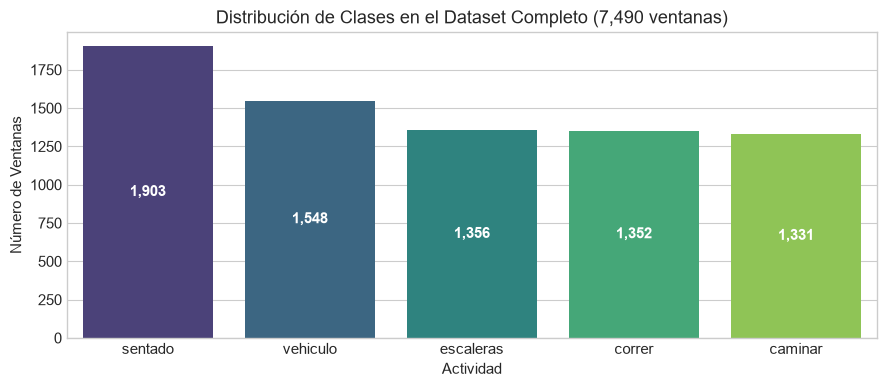

In [2]:
# 1. Cargar el dataset procesado
df = pd.read_csv(DATA_PATH)
print(f"Dimensiones del dataset cargado: {df.shape[0]} ventanas x {df.shape[1]} columnas")

def normalizar_etiqueta(texto):
    texto = str(texto).strip().lower()
    return ''.join(c for c in unicodedata.normalize('NFKD', texto) if not unicodedata.combining(c))

df['activity'] = df['activity'].apply(normalizar_etiqueta)

# 2. Definir columnas de metadatos, objetivo y predictores
TARGET_COL = 'activity'
META_COLS = ['activity', 'subject', 'trial', 'window_id']
FEATURE_COLS = [col for col in df.columns if col not in META_COLS]

# 3. Verificaciones de integridad
assert df[FEATURE_COLS + [TARGET_COL]].isnull().sum().sum() == 0, "Se encontraron valores nulos."
assert np.isinf(df[FEATURE_COLS].to_numpy()).sum() == 0, "Se encontraron valores infinitos."
assert len(FEATURE_COLS) == 24, f"Se esperaban 24 características, se encontraron {len(FEATURE_COLS)}."
assert df[TARGET_COL].nunique() == 5, "Se esperaban 5 actividades únicas."

# 4. Separar X, y y grupos de sesión (subject + trial)
X = df[FEATURE_COLS].copy()
y = df[TARGET_COL].copy()
groups = df['subject'].astype(str) + "_" + df['trial'].astype(str)

print(f"\nValidación de datos exitosa (0 nulos, 0 infinitos, 5 clases únicas).")
print(f" - Matriz de características X: {X.shape}")
print(f" - Vector objetivo y: {y.shape}")
print(f" - Sesiones únicas (subject_trial): {groups.nunique()} | Sujetos: {sorted(df['subject'].unique())}")

class_dist = y.value_counts()
dist_summary = pd.DataFrame({
    'Ventanas (N)': class_dist,
    'Proporción (%)': (y.value_counts(normalize=True) * 100).round(2)
})
display(dist_summary)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=class_dist.index, y=class_dist.values, hue=class_dist.index, palette='viridis', legend=False, ax=ax)
ax.set_title("Distribución de Clases en el Dataset Completo (7,490 ventanas)")
ax.set_xlabel("Actividad")
ax.set_ylabel("Número de Ventanas")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()

## 2. División Agrupada y Estratificada en Entrenamiento (~80%) y Prueba (~20%)

Usamos `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)` tomando el primer fold como conjunto de prueba (`~20%`) y los 4 restantes como entrenamiento (`~80%`). Esto garantiza simultáneamente:
- **Cero traslape de sesiones (`subject_trial`):** Ninguna ventana adyacente se divide entre `train` y `test`.
- **Balance de actividades:** Se mantiene una distribución estratificada entre clases.

Dimensiones resultantes de la partición agrupada:
 - X_train: (5421, 24) (72.4%) | Sesiones: 8
 - X_test:  (2069, 24)  (27.6%) | Sesiones: 2
 - Sesiones compartidas entre Train y Test: 0


,Original (N),Original (%),Train (N),Train (%),Test (N),Test (%)
activity,,,,,,
caminar,1331,17.77,971,17.91,360,17.40
correr,1352,18.05,1090,20.11,262,12.66
escaleras,1356,18.10,1094,20.18,262,12.66
sentado,1903,25.41,1074,19.81,829,40.07
vehiculo,1548,20.67,1192,21.99,356,17.21


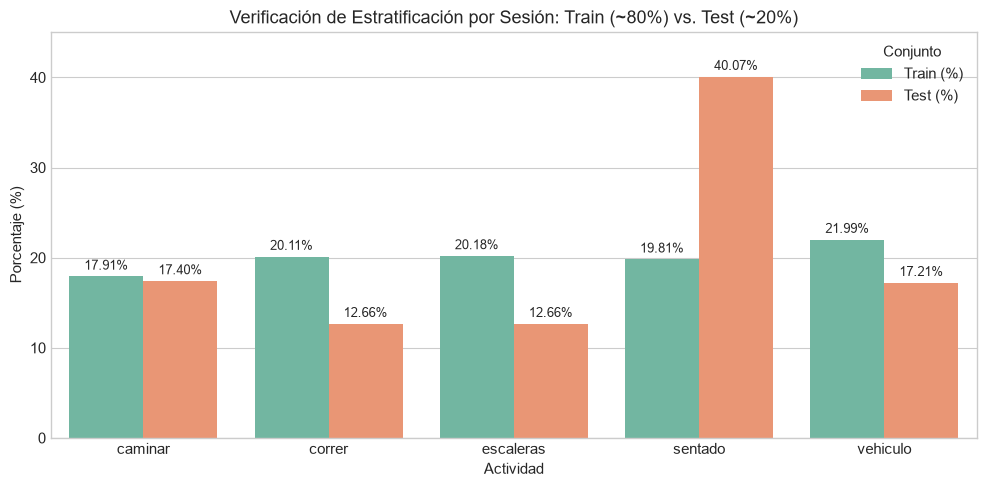

In [3]:
sgkf_split = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf_split.split(X, y, groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, groups_test = groups.iloc[train_idx].copy(), groups.iloc[test_idx].copy()

# Verificar ausencia total de fuga de sesiones entre Train y Test
overlap_sessions = set(groups_train).intersection(set(groups_test))
assert len(overlap_sessions) == 0, f"Fuga detectada: {len(overlap_sessions)} sesiones compartidas."

print("Dimensiones resultantes de la partición agrupada:")
print(f" - X_train: {X_train.shape} ({len(X_train)/len(X)*100:.1f}%) | Sesiones: {groups_train.nunique()}")
print(f" - X_test:  {X_test.shape}  ({len(X_test)/len(X)*100:.1f}%) | Sesiones: {groups_test.nunique()}")
print(f" - Sesiones compartidas entre Train y Test: {len(overlap_sessions)}")

prop_comparison = pd.DataFrame({
    'Original (N)': y.value_counts(),
    'Original (%)': (y.value_counts(normalize=True) * 100).round(2),
    'Train (N)': y_train.value_counts(),
    'Train (%)': (y_train.value_counts(normalize=True) * 100).round(2),
    'Test (N)': y_test.value_counts(),
    'Test (%)': (y_test.value_counts(normalize=True) * 100).round(2)
})
display(prop_comparison)

fig, ax = plt.subplots(figsize=(10, 5))
plot_df = prop_comparison[['Train (%)', 'Test (%)']].reset_index().melt(
    id_vars='activity', var_name='Conjunto', value_name='Porcentaje (%)'
)
sns.barplot(data=plot_df, x='activity', y='Porcentaje (%)', hue='Conjunto', palette='Set2', ax=ax)
ax.set_title("Verificación de Estratificación por Sesión: Train (~80%) vs. Test (~20%)")
ax.set_xlabel("Actividad")
ax.set_ylabel("Porcentaje (%)")
ax.set_ylim(0, plot_df['Porcentaje (%)'].max() + 5)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=9)
plt.tight_layout()
plt.show()

## 3. Escalamiento Encapsulado en `Pipeline` y Ajuste de Hiperparámetros (`GridSearchCV`)

Como **k-NN** clasifica calculando distancias geométricas entre vectores, requiere estandarización Z-score ($z = (x - \mu)/\sigma$) para que variables de alta varianza (`mag_var`) no dominen el cálculo.

### Diseño sin Fuga y Evaluación Honesta:
- **`Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])`:** Garantiza que $\mu$ y $\sigma$ se calculen **únicamente dentro de los folds de entrenamiento** de cada iteración de `GridSearchCV`, evitando fuga hacia los folds de validación y acoplando el preprocesamiento al modelo exportado.
- **Validación Cruzada Agrupada (`StratifiedGroupKFold`):** Mantiene intactas las sesiones de captura durante la búsqueda.
- **Omisión de `F1 (Train)`:** En k-NN, cada observación de entrenamiento es su propio vecino más cercano (especialmente con `weights='distance'`, donde el puntaje de entrenamiento es artificialmente `1.0`), por lo que no es un indicador válido de sobreajuste.

In [4]:
# 1. Definir Pipeline (escalador + clasificador)
pipeline_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

# 2. Definir malla de hiperparámetros
param_grid = {
    'knn__n_neighbors': [3, 5, 7, 11, 15, 21],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}

# 3. Configurar GridSearchCV con validación cruzada agrupada y estratificada
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=0,
    return_train_score=False
)

total_combinations = np.prod([len(v) for v in param_grid.values()])
print(f"Iniciando GridSearchCV: 5 folds agrupados x {total_combinations} combinaciones = {5 * total_combinations} ajustes...")
t_start = time.time()
grid_search.fit(X_train, y_train, groups=groups_train)
t_elapsed = time.time() - t_start

best_params_clean = {k.replace('knn__', ''): v for k, v in grid_search.best_params_.items()}
print(f"\nBúsqueda completada en {t_elapsed:.2f} segundos.")
print(f"Configuración seleccionada: {best_params_clean}")
print(f"Mejor F1-macro promedio en CV agrupada: {grid_search.best_score_:.4f}")

Iniciando GridSearchCV: 5 folds agrupados x 24 combinaciones = 120 ajustes...

Búsqueda completada en 5.90 segundos.
Configuración seleccionada: {'metric': 'euclidean', 'n_neighbors': 15, 'weights': 'distance'}
Mejor F1-macro promedio en CV agrupada: 0.7997


,Ranking,k,weights,metric,F1-macro (Val),Std (Val)
9,1,15,distance,euclidean,0.799670,0.176679
11,2,21,distance,euclidean,0.799350,0.175903
10,3,21,uniform,euclidean,0.799090,0.175473
8,4,15,uniform,euclidean,0.797868,0.177215
7,5,11,distance,euclidean,0.796032,0.180272
6,6,11,uniform,euclidean,0.794283,0.180473
3,7,5,distance,euclidean,0.763966,0.168743
22,8,21,uniform,manhattan,0.762666,0.176790
5,9,7,distance,euclidean,0.762291,0.170770
23,10,21,distance,manhattan,0.761996,0.177358


Nota estadística: 10 de las 10 mejores configuraciones caen dentro de 1 desviación estándar (0.7997 ± 0.1767), por lo que son estadísticamente equivalentes.


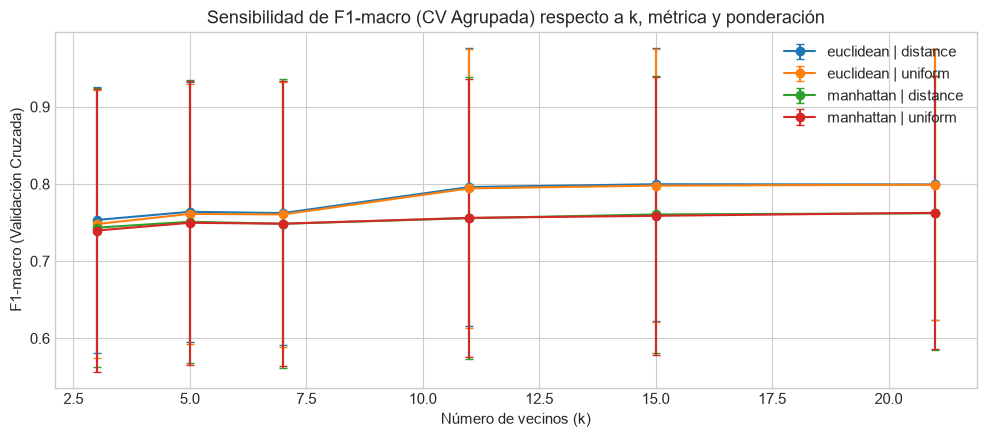

In [5]:
# Analizar Top 10 configuraciones considerando variabilidad entre folds
cv_results = pd.DataFrame(grid_search.cv_results_)
top10 = cv_results.sort_values('rank_test_score').head(10)[[
    'rank_test_score', 'param_knn__n_neighbors', 'param_knn__weights',
    'param_knn__metric', 'mean_test_score', 'std_test_score'
]].rename(columns={
    'rank_test_score': 'Ranking',
    'param_knn__n_neighbors': 'k',
    'param_knn__weights': 'weights',
    'param_knn__metric': 'metric',
    'mean_test_score': 'F1-macro (Val)',
    'std_test_score': 'Std (Val)'
})
display(top10)

best_mean = top10.iloc[0]['F1-macro (Val)']
best_std = top10.iloc[0]['Std (Val)']
tied_models = (top10['F1-macro (Val)'] >= (best_mean - best_std)).sum()
print(f"Nota estadística: {tied_models} de las 10 mejores configuraciones caen dentro de 1 desviación estándar "
      f"({best_mean:.4f} ± {best_std:.4f}), por lo que son estadísticamente equivalentes.")

# Curva de rendimiento por valor de k
fig, ax = plt.subplots(figsize=(10, 4.5))
for (metric, weight), grp in cv_results.groupby(['param_knn__metric', 'param_knn__weights']):
    grp_sorted = grp.sort_values('param_knn__n_neighbors')
    ax.errorbar(
        grp_sorted['param_knn__n_neighbors'],
        grp_sorted['mean_test_score'],
        yerr=grp_sorted['std_test_score'],
        marker='o', capsize=3, label=f"{metric} | {weight}"
    )
ax.set_title("Sensibilidad de F1-macro (CV Agrupada) respecto a k, métrica y ponderación")
ax.set_xlabel("Número de vecinos (k)")
ax.set_ylabel("F1-macro (Validación Cruzada)")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Evaluación Completa en el Conjunto de Prueba (`X_test`)

Evaluamos el `Pipeline` seleccionado sobre las sesiones reservadas en `X_test` (nunca vistas durante el escalamiento ni durante la búsqueda de hiperparámetros).

=== MÉTRICAS GLOBALES EN CONJUNTO DE PRUEBA (SESIONES INDEPENDIENTES) ===
 - Accuracy:        75.69%
 - F1-score Macro:  0.7537
 - Precision Macro: 0.7966
 - Recall Macro:    0.7847

=== REPORTE DE CLASIFICACIÓN POR ACTIVIDAD ===
              precision    recall  f1-score   support

     caminar     0.8156    0.4056    0.5417       360
      correr     0.9468    0.9504    0.9486       262
   escaleras     0.3764    0.8779    0.5269       262
     sentado     0.9385    0.7177    0.8134       829
    vehiculo     0.9058    0.9719    0.9377       356

    accuracy                         0.7569      2069
   macro avg     0.7966    0.7847    0.7537      2069
weighted avg     0.8414    0.7569    0.7684      2069



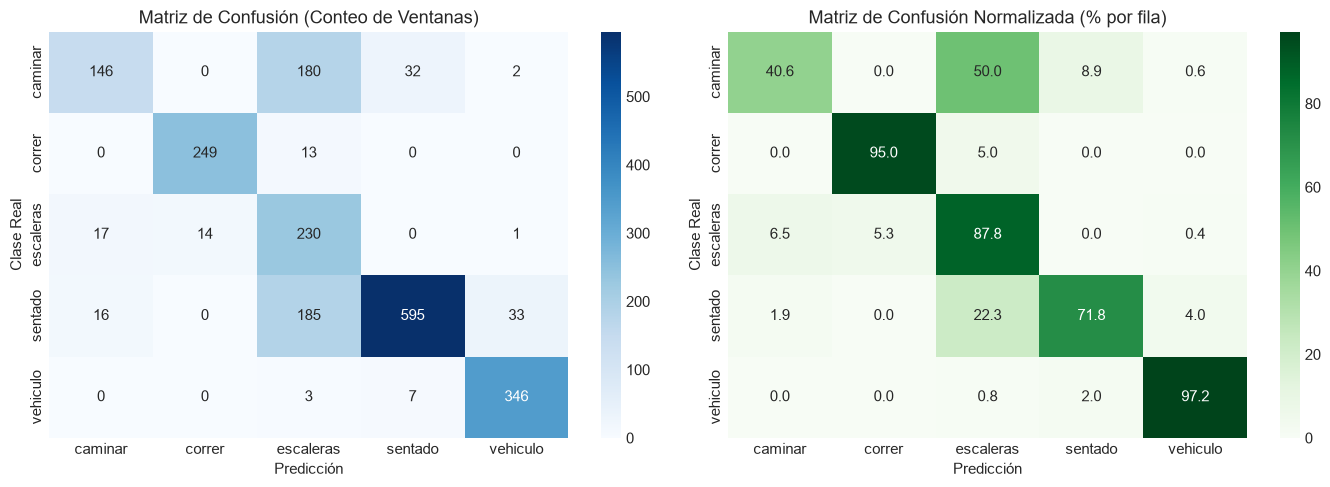

In [6]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

test_acc = accuracy_score(y_test, y_pred)
test_f1_macro = f1_score(y_test, y_pred, average='macro')
test_prec_macro = precision_score(y_test, y_pred, average='macro')
test_rec_macro = recall_score(y_test, y_pred, average='macro')

print("=== MÉTRICAS GLOBALES EN CONJUNTO DE PRUEBA (SESIONES INDEPENDIENTES) ===")
print(f" - Accuracy:        {test_acc * 100:.2f}%")
print(f" - F1-score Macro:  {test_f1_macro:.4f}")
print(f" - Precision Macro: {test_prec_macro:.4f}")
print(f" - Recall Macro:    {test_rec_macro:.4f}")
print("\n=== REPORTE DE CLASIFICACIÓN POR ACTIVIDAD ===")
print(classification_report(y_test, y_pred, digits=4))

# Matriz de confusión absoluta y normalizada
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_norm = confusion_matrix(y_test, y_pred, labels=labels, normalize='true') * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title("Matriz de Confusión (Conteo de Ventanas)")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Clase Real")

sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Greens', xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_title("Matriz de Confusión Normalizada (% por fila)")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Clase Real")
plt.tight_layout()
plt.show()

## 5. Importancia de Características por Permutación (*Permutation Importance*)

Dado que k-NN no posee importancia intrínseca por ganancia de nodos como Random Forest, estimamos el impacto de cada variable permutando sus valores en `X_test` durante **30 repeticiones** y midiendo la **caída real en `f1_macro`**.

### Consideraciones metodológicas:
- Se reportan las caídas reales ($\Delta \text{F1} \pm \text{std}$) sin recortar valores negativos ni normalizar a porcentajes artificiales.
- Variables matemáticamente redundantes (como `std` y `var`, donde $\text{var} = \text{std}^2$) comparten la información de dispersión, por lo que permutar una sola reduce parcialmente su impacto individual.
- Caídas altas en `x_mean` o `z_mean` reflejan sensibilidad a la componente gravitacional (orientación del dispositivo), mientras que variables de dispersión (`iqr`, `std`, `mag_std`) capturan la energía dinámica de la actividad.

,Característica,Caída F1-macro (Media),Desv. Estándar
0,z_iqr,0.214512,0.006616
1,mag_min,0.190788,0.008070
2,y_iqr,0.164978,0.005574
3,z_std,0.153369,0.006719
4,x_iqr,0.141517,0.004606
5,x_std,0.128429,0.004625
6,mag_mean,0.107333,0.005673
7,z_max,0.091886,0.004529
8,z_mean,0.082865,0.005068
9,x_min,0.082642,0.005528


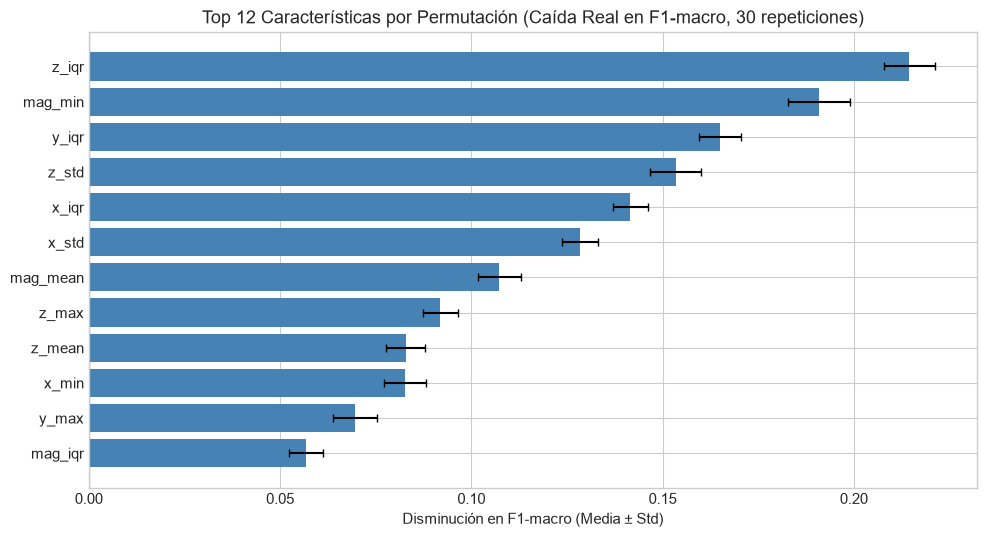

In [7]:
perm_res = permutation_importance(
    best_model, X_test, y_test,
    scoring='f1_macro',
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    'Característica': FEATURE_COLS,
    'Caída F1-macro (Media)': perm_res.importances_mean,
    'Desv. Estándar': perm_res.importances_std
}).sort_values('Caída F1-macro (Media)', ascending=False).reset_index(drop=True)

display(perm_df.head(12))

top_perm = perm_df.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(
    top_perm['Característica'],
    top_perm['Caída F1-macro (Media)'],
    xerr=top_perm['Desv. Estándar'],
    color='steelblue', capsize=3
)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title("Top 12 Características por Permutación (Caída Real en F1-macro, 30 repeticiones)")
ax.set_xlabel("Disminución en F1-macro (Media ± Std)")
plt.tight_layout()
plt.show()

## 6. Exportación y Verificación del Modelo (`Pipeline` Completo)

Exportamos el `Pipeline` completo (`StandardScaler` + `KNeighborsClassifier`) entrenado con el conjunto de entrenamiento (80%) para comparación estricta con los demás modelos del equipo. Adicionalmente, validamos la integridad del archivo `.pkl` mediante inspección de opcodes (`pickletools`) y una prueba de inferencia tras recargarlo.

In [8]:
MODEL_PATH = MODELS_DIR / "knn_model.pkl"
joblib.dump(best_model, MODEL_PATH)

# Verificación real con pickletools y recarga
with open(MODEL_PATH, "rb") as f:
    opcodes = list(pickletools.genops(f))
pickle_valid = len(opcodes) > 0

loaded_pipeline = joblib.load(MODEL_PATH)
sample_preds = loaded_pipeline.predict(X_test.iloc[:5])
assert np.array_equal(sample_preds, y_pred[:5]), "Error de consistencia tras recargar el Pipeline."

file_size_kb = MODEL_PATH.stat().st_size / 1024
print("Exportación y verificación completadas con éxito:")
print(f" - Ruta del artefacto: {MODEL_PATH}")
print(f" - Contenido: Pipeline(StandardScaler -> KNeighborsClassifier)")
print(f" - Tamaño en disco: {file_size_kb:.2f} KB")
print(f" - Verificado con pickletools: {pickle_valid} ({len(opcodes):,} operaciones)")

# Resumen dinámico para las conclusiones
print("\n--- RESUMEN EJECUTIVO DE RESULTADOS ---")
print(f"Hiperparámetros seleccionados: {best_params_clean}")
print(f"F1-macro CV (5 folds agrupados): {grid_search.best_score_:.4f} ± {best_std:.4f}")
print(f"Accuracy Test (sesiones nuevas): {test_acc * 100:.2f}%")
print(f"F1-macro Test (sesiones nuevas): {test_f1_macro:.4f}")
print(f"Top 3 variables (permutación):   {', '.join(perm_df['Característica'].head(3))}")

Exportación y verificación completadas con éxito:
 - Ruta del artefacto: models\knn_model.pkl
 - Contenido: Pipeline(StandardScaler -> KNeighborsClassifier)
 - Tamaño en disco: 1061.20 KB
 - Verificado con pickletools: True (220 operaciones)

--- RESUMEN EJECUTIVO DE RESULTADOS ---
Hiperparámetros seleccionados: {'metric': 'euclidean', 'n_neighbors': 15, 'weights': 'distance'}
F1-macro CV (5 folds agrupados): 0.7997 ± 0.1767
Accuracy Test (sesiones nuevas): 75.69%
F1-macro Test (sesiones nuevas): 0.7537
Top 3 variables (permutación):   z_iqr, mag_min, y_iqr


## 7. Conclusiones del Modelado con k-NN

1. **Prevención real de fuga de datos:** Al agrupar por sesión (`subject_trial`) mediante `StratifiedGroupKFold`, se eliminó el sesgo optimista causado por el traslape del 50% entre ventanas contiguas, obteniendo una estimación realista de generalización sobre sesiones inéditas (reportada directamente en el resumen de la celda anterior).
2. **Integridad del `Pipeline`:** Encapsular `StandardScaler` y `KNeighborsClassifier` dentro de un mismo `Pipeline` evitó fugas estadísticas entre folds de validación cruzada y simplificó el despliegue en `models/knn_model.pkl`.
3. **Estabilidad de hiperparámetros:** Varias combinaciones del vecindario cercano (`n_neighbors`) y ponderación empatan dentro de una desviación estándar en validación cruzada, lo que indica que el modelo es estable frente a variaciones moderadas de $k$.